In [ ]:
# 6. Develop a Convolutional Neural Network using TensorFlow/Keras to 
# classify ASL alphabet gestures using the Sign Language MNIST dataset. 
# Reshape the images into 28 × 28 × 1 format, apply convolution and 
# pooling operations, train the model and display test accuracy. 

In [1]:
# Step 1: Import required libraries

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

In [2]:
# Step 2: Load training and testing datasets

train_data = pd.read_csv('sign_mnist_train.csv')
test_data = pd.read_csv('sign_mnist_test.csv')

print("Training Dataset Shape:", train_data.shape)
print("Testing Dataset Shape:", test_data.shape)

Training Dataset Shape: (27455, 785)
Testing Dataset Shape: (7172, 785)


In [3]:
# Step 3: Separate features and labels

X_train = train_data.drop('label', axis=1).values
y_train = train_data['label'].values

X_test = test_data.drop('label', axis=1).values
y_test = test_data['label'].values

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (27455, 784)
y_train: (27455,)
X_test: (7172, 784)
y_test: (7172,)


In [4]:
# Step 4: Convert labels into 24 consecutive classes

classes = np.sort(np.unique(y_train))

label_map = {
    label: i for i, label in enumerate(classes)
}

y_train = np.array([label_map[x] for x in y_train])
y_test = np.array([label_map[x] for x in y_test])

print("Number of Classes:", len(classes))
print("Classes:", classes)

Number of Classes: 24
Classes: [ 0  1  2  3  4  5  6  7  8 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]


In [5]:
# Step 5: Normalize pixel values

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print("Training Data Normalized")
print("Testing Data Normalized")

Training Data Normalized
Testing Data Normalized


In [6]:
# Step 6: Reshape images for CNN

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training Image Shape:", X_train.shape)
print("Testing Image Shape:", X_test.shape)

Training Image Shape: (27455, 28, 28, 1)
Testing Image Shape: (7172, 28, 28, 1)


In [7]:
# Step 7: Split training data for validation

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training Data:", X_train.shape)
print("Validation Data:", X_val.shape)

Training Data: (21964, 28, 28, 1)
Validation Data: (5491, 28, 28, 1)


In [8]:
# Step 8: Build Convolutional Neural Network

model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(28, 28, 1)),

    # First Convolutional Layer
    tf.keras.layers.Conv2D(
        32, (3, 3), activation='relu'
    ),

    # First Max Pooling Layer
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second Convolutional Layer
    tf.keras.layers.Conv2D(
        64, (3, 3), activation='relu'
    ),

    # Second Max Pooling Layer
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Flatten Layer
    tf.keras.layers.Flatten(),

    # Fully Connected Layer
    tf.keras.layers.Dense(128, activation='relu'),

    # Output Layer
    tf.keras.layers.Dense(24, activation='softmax')
])

In [9]:
# Step 9: Compile the CNN model

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model Compiled Successfully!")

Model Compiled Successfully!


In [10]:
# Step 10: Display model summary

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 24)                  │           3,096 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 226,840 (886.09 KB)

 Trainable params: 226,840 (886.09 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
# Step 11: Train the CNN model

history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_data=(X_val, y_val)
)

Epoch 1/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 11s 47ms/step - accuracy: 0.4988 - loss: 1.7341 - val_accuracy: 0.8046 - val_loss: 0.6524
Epoch 2/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - accuracy: 0.8911 - loss: 0.3901 - val_accuracy: 0.9594 - val_loss: 0.2027
Epoch 3/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - accuracy: 0.9725 - loss: 0.1377 - val_accuracy: 0.9922 - val_loss: 0.0674
Epoch 4/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - accuracy: 0.9961 - loss: 0.0471 - val_accuracy: 0.9971 - val_loss: 0.0323
Epoch 5/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - accuracy: 0.9992 - loss: 0.0199 - val_accuracy: 0.9998 - val_loss: 0.0139
Epoch 6/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - accuracy: 0.9999 - loss: 0.0102 - val_accuracy: 1.0000 - val_loss: 0.0079
Epoch 7/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 7s 41ms/step - accuracy: 1.0000 - loss: 0.0061 - val_accuracy: 1.0000 - val_loss: 0.0051
Epoch 8/10
172/172 ━━━━━━━━━━━━━━━━━━━━ 6s 37ms/step - accuracy: 1.0000 - loss: 0.0041 - val_acc

In [12]:
# Step 12: Evaluate the CNN model

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test
)

print("\nTest Loss:", test_loss)

print("Test Accuracy: {:.2f}%".format(
    test_accuracy * 100
))

225/225 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8878 - loss: 0.4734

Test Loss: 0.47344130277633667
Test Accuracy: 88.78%


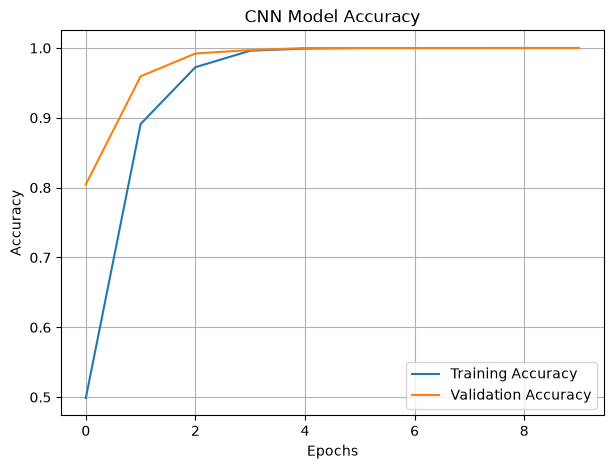

In [13]:
# Step 13: Display accuracy graph

plt.figure(figsize=(7, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('CNN Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(True)
plt.show()

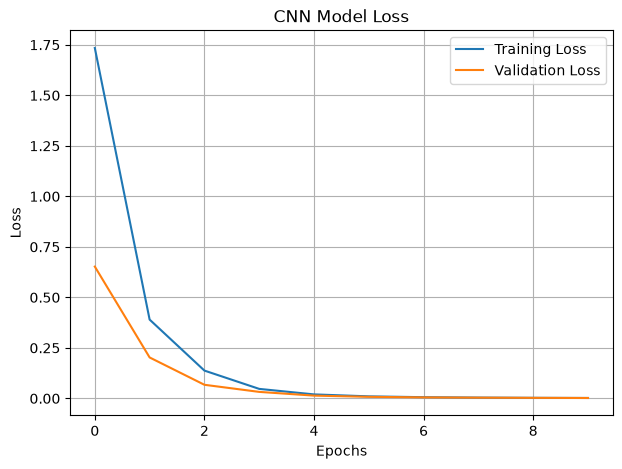

In [14]:
# Step 14: Display loss graph

plt.figure(figsize=(7, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('CNN Model Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)
plt.show()